# 09C — Stopwatch Twins discovery

**The scouting question.** Two prospects of the same position run nearly the same official forty. Traditional evaluation sees two equivalent speed performances. *What does tracking measure between them — and is it larger than its own uncertainty?*

**Matching (pre-draft information only, tolerances declared in `TwinConfig` before any pair was looked at).** Same position group · official forty within the caliper · the 10-yard split and the body measurements are recorded as *matched / not matched* flags, so a scout can tighten the comparison.

**Differences.** For every pair and every Combine curve feature of 09B: the difference, the standard error **of the difference** (repeat-attempt variation of both athletes) and a verdict — `distinguishable`, `not_distinguishable`, `insufficient_evidence`, `not_observed`. A difference is reported even when it is not distinguishable, with that verdict.

**Ranking.** Within position, by the largest difference in standard errors, using only features whose evidence status is not *unstable* or *insufficient*.

**Read the share against chance.** With a 95 % criterion, about 5 % of pairs would be called distinguishable on a feature if no pair truly differed. Pairs share athletes: the share is descriptive, not a test.

**No NFL quantity** enters any table of this notebook (`assert_no_nfl_columns`).

**Prerequisites (same `RUN_MODE`).** 01, 02, 07D, 09B. Optional: 06B (TCN-B fingerprint distance, shown as a mathematical similarity).

In [1]:
RUN_MODE = 'full'             # 'smoke' | 'full'
SEED = 20261011
FORCE_REBUILD = False         # interface parity: every table of this notebook is recomputed on each run
SAVE_TABLES = True
SAVE_FIGURES = True
NUM_WORKERS = 0
EXPERIMENT_VERSION = '09C.1'
FORTY_TOL = 0.03              # s — official forty caliper (the 07D case caliper)
TEN_TOL = 0.03                # s — 10-yard split flag
N_STORIES = 3                 # top-ranked pairs drawn in this notebook (one per position, largest difference first)
SHOW_TABLES = True

In [2]:
from nflbdb.data.config import Phase01Config, configure_runtime

cfg = Phase01Config.load()
configure_runtime(cfg)

import polars as pl
from IPython.display import Markdown, display

from nflbdb.data.utils import utc_now
from nflbdb.research.advanced_movement import checkpoint as ck
from nflbdb.research.advanced_movement import config as amc
from nflbdb.research.advanced_movement import intelligence_figures as ifg
from nflbdb.research.advanced_movement import intelligence_validation as iv
from nflbdb.research.advanced_movement import movement_matching as mm
from nflbdb.research.advanced_movement import sequences as seq
from nflbdb.research.advanced_movement import stopwatch_twins as stw
from nflbdb.research.advanced_movement.artifacts import IntelligenceStore, MissingArtifactError
from nflbdb.research.advanced_movement.scoring import figures as sfig
from nflbdb.research.advanced_movement.scoring import fingerprint as fp
from nflbdb.research.advanced_movement.scoring import scorecards as sc

controls = amc.NotebookControls(run_mode=RUN_MODE, force_rebuild=FORCE_REBUILD, save_figures=SAVE_FIGURES, save_tables=SAVE_TABLES,
                                seed=SEED, num_workers=NUM_WORKERS).validate()
store = IntelligenceStore(cfg, controls)
up, SC, T = store.upstream, store.scoring, store.transfer
amc.seed_everything(controls.seed)
TC = stw.TwinConfig(forty_tol=FORTY_TOL, ten_tol=TEN_TOL)
NB = {'01': '01_sequence_eda_and_alignment.ipynb', '02': '02_functional_pca_baseline.ipynb', '06B': '06b_combine_to_nfl_transfer_benchmark.ipynb',
      '07D': '07d_athletic_fingerprint_scorecard.ipynb', '09B': '09b_cross_domain_movement_matching.ipynb', '09C': '09c_stopwatch_twins_discovery.ipynb'}

profile = SC.require(sc.PROFILE, NB['07D'])
prospect = store.require(mm.PROSPECT, NB['09B'])
evidence = store.require(mm.EVIDENCE, NB['09B'])
frames = up.require(seq.SEQ_FRAMES, NB['01'])
windows = up.require(ck.WINDOWS, NB['02'])
for name, df in (('profile', profile), ('prospect curve features', prospect)):
    sc.assert_no_nfl_columns(df, name)
ORDER = dict(zip(windows['seq_id'].to_list(), windows['attempt_order'].to_list()))
try:
    rep = T.require_named('transfer_attempt_representations_outer', NB['06B'])
    DIST = fp.distance_lookup(fp.fold_embeddings(rep, ORDER))
except MissingArtifactError as e:
    print('OPTIONAL INPUT ABSENT — fold-fitted TCN representation (fingerprint distance):', e)
    DIST = None
PROV = {'notebook': NB['09C'], 'experiment_version': EXPERIMENT_VERSION, 'run_mode': controls.run_mode, 'seed': controls.seed, 'twin_config': TC.params(),
        'nfl_inputs': 'none'}
save = lambda df, c: store.write(df, c, '09C', PROV) if controls.save_tables else df
label = 'SMOKE — wiring check, numbers are not results' if controls.smoke else 'FULL'
display(Markdown(f'**Run mode: `{controls.run_mode}`** ({label}) · {profile.height} Combine profiles · fingerprint distance {"available" if DIST is not None else "NOT available"}'))

**Run mode: `full`** (FULL) · 510 Combine profiles · fingerprint distance available

## 1 · Synthetic checks

Pairs are exactly those inside the caliper and of the same position; an NFL column in a matching table is refused; a planted difference is distinguishable and no difference is not; time features are oriented; case selection is deterministic and never ordered by an NFL quantity.

In [3]:
validation = iv.run_all(iv.CHECKS_TWINS)
with pl.Config(fmt_str_lengths=220, tbl_rows=-1):
    display(validation)
iv.assert_all_passed(validation)

check,status,detail
str,str,str
"""twin_matching_uses_pre_draft_information_only""","""PASS""","""twins are matched on official results only, differences are tested on the SE of the difference, time features are oriented"""
"""case_selection_rules""","""PASS""","""ten declared case types, deterministic, pre-draft; absent types are reported; NFL exposure is eligibility only"""


## 2 · Comparable-athlete index and measured differences

13:10:18 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:09C] stopwatch_twin_differences: 26,128 rows → warehouse/gold/advanced_movement/intelligence_v1/stopwatch_twin_differences.parquet
13:10:18 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:09C] stopwatch_twins: 3,266 rows → warehouse/gold/advanced_movement/intelligence_v1/stopwatch_twins.parquet
13:10:18 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:09C] stopwatch_twin_summary: 48 rows → warehouse/gold/advanced_movement/intelligence_v1/stopwatch_twin_summary.parquet


3,266 pairs inside the caliper · 3,128 ranked (at least 3 comparable curve features)


position_group,n_pairs,ten_matched,body_matched,with_a_distinguishable_feature
str,u32,u32,u32,u32
"""DB""",1173,745,615,845
"""DL""",359,244,134,235
"""OL""",623,351,289,351
"""TE""",95,54,63,67
"""WR""",1016,704,375,599


position_group,feature,n_pairs,n_tested,n_distinguishable,share_distinguishable,median_abs_difference,expected_by_chance
str,str,i64,i64,i64,f64,f64,f64
"""ALL""","""acc_2_4""",3266,3128,454,0.145141,0.503679,0.05
"""ALL""","""acc_4_6""",3266,3128,514,0.164322,0.424359,0.05
"""ALL""","""acc_6_8""",3266,3128,436,0.139386,0.258279,0.05
"""ALL""","""speed_10yd""",3266,3128,523,0.167199,0.144092,0.05
"""ALL""","""speed_20yd""",3266,3128,813,0.25991,0.098901,0.05
"""ALL""","""speed_30yd""",3266,3128,1189,0.380115,0.126174,0.05
"""ALL""","""time_4_8""",3266,3128,643,0.205563,0.072256,0.05
"""ALL""","""top_speed""",3266,3128,1252,0.400256,0.144118,0.05
"""DB""","""acc_2_4""",1173,1123,118,0.105076,0.513648,0.05


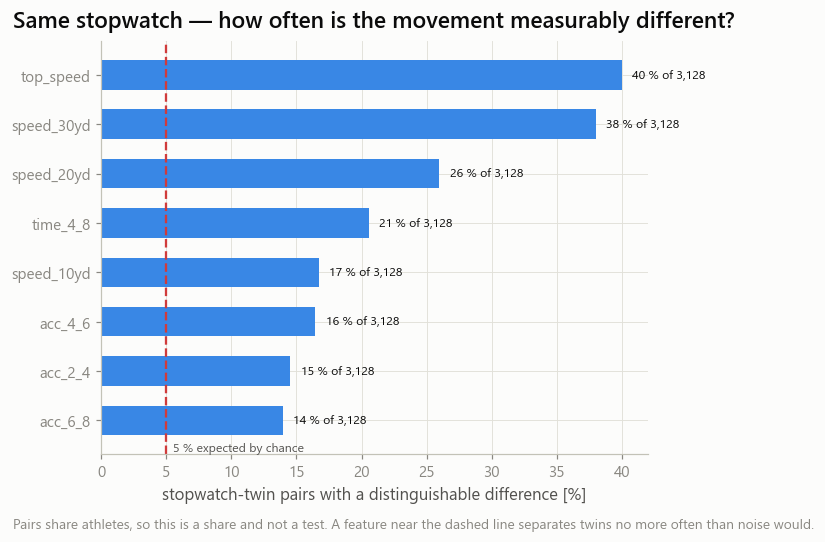

In [4]:
pairs = stw.twin_index(profile, TC, DIST)
diffs = save(stw.difference_table(pairs, prospect, evidence), stw.DIFFS)
twins = save(stw.rank_twins(pairs, diffs, TC), stw.TWINS)
summary = save(stw.twin_summary(twins, diffs), stw.SUMMARY)
print(f'{twins.height:,} pairs inside the caliper · {int(twins["rank_in_position"].is_not_null().sum()):,} ranked (at least {TC.min_features} comparable curve features)')
with pl.Config(tbl_rows=-1, tbl_width_chars=240):
    display(twins.group_by('position_group').agg(pl.len().alias('n_pairs'), pl.col('ten_matched').sum().alias('ten_matched'), pl.col('body_matched').sum().alias('body_matched'),
                                                 (pl.col('n_distinguishable') >= 1).sum().alias('with_a_distinguishable_feature')).sort('position_group'))
    if SHOW_TABLES:
        display(summary)
store.show(ifg.fig_twin_summary(summary), 'AM09C_01_twin_distinguishability', {'summary': summary}, publication=True, source='stopwatch_twin_summary',
           n=f'{twins.height:,} pairs (not independent)')

## 3 · Ranked matched-prospect pairs

The ten top-ranked pairs of each position. `max_abs_z` is the largest difference in standard errors of the difference; `top_feature` and `top_phase` say where it sits.

In [5]:
top = twins.filter(pl.col('rank_in_position') <= 10)
with pl.Config(tbl_rows=-1, tbl_width_chars=260, fmt_str_lengths=40):
    display(top.select('position_group', 'rank_in_position', 'name_a', 'name_b', 'forty_a', 'forty_b', 'd_ten', 'ten_matched', 'body_matched', 'tier_a', 'tier_b',
                       'n_distinguishable', 'max_abs_z', 'top_feature', 'top_phase'))

position_group,rank_in_position,name_a,name_b,forty_a,forty_b,d_ten,ten_matched,body_matched,tier_a,tier_b,n_distinguishable,max_abs_z,top_feature,top_phase
str,i64,str,str,f64,f64,f64,bool,bool,str,str,i64,f64,str,str
"""DB""",1,"""Jaylen Key""","""Rayuan Lane""",4.6,4.57,-0.03,true,true,"""medium""","""high""",5,8.890676,"""speed_30yd""","""late"""
"""DB""",2,"""DeMarcco Hellams""","""Jaylen Key""",4.57,4.6,0.02,true,true,"""high""","""medium""",6,8.773158,"""speed_30yd""","""late"""
"""DB""",3,"""Kris Abrams-Draine""","""Jaylin Smith""",4.44,4.45,0.07,false,true,"""high""","""medium""",3,8.608529,"""top_speed""","""late"""
"""DB""",4,"""Javon Bullard""","""Jaylen Reed""",4.47,4.49,0.0,true,true,"""low""","""low""",3,8.266676,"""speed_10yd""","""early"""
"""DB""",5,"""Javon Bullard""","""Jaylin Smith""",4.47,4.45,0.09,false,true,"""low""","""medium""",6,8.070016,"""speed_30yd""","""late"""
"""DB""",6,"""Sydney Brown""","""Alijah Clark""",4.47,4.5,0.02,true,false,"""high""","""high""",3,7.931909,"""top_speed""","""late"""
"""DB""",7,"""Javon Bullard""","""Quincy Riley""",4.47,4.48,0.03,true,true,"""low""","""high""",4,7.92014,"""speed_10yd""","""early"""
"""DB""",8,"""Sydney Brown""","""Terrion Arnold""",4.47,4.5,0.03,true,false,"""high""","""high""",3,7.908323,"""top_speed""","""late"""
"""DB""",9,"""Javon Bullard""","""Nohl Williams""",4.47,4.5,0.03,true,true,"""low""","""high""",4,7.904687,"""speed_10yd""","""early"""


## 4 · The signature figure — same stopwatch, different movement

For the top-ranked pair of each position (largest difference first, at most `N_STORIES`): what the stopwatch sees, what tracking sees (every recorded attempt of both athletes against the position's 10–90 % band), and whether each difference exceeds its uncertainty. Then the acceleration-versus-speed profile and the time gained or lost through each speed band.

These pairs are chosen by rank only. They are illustrations of what the tables hold.

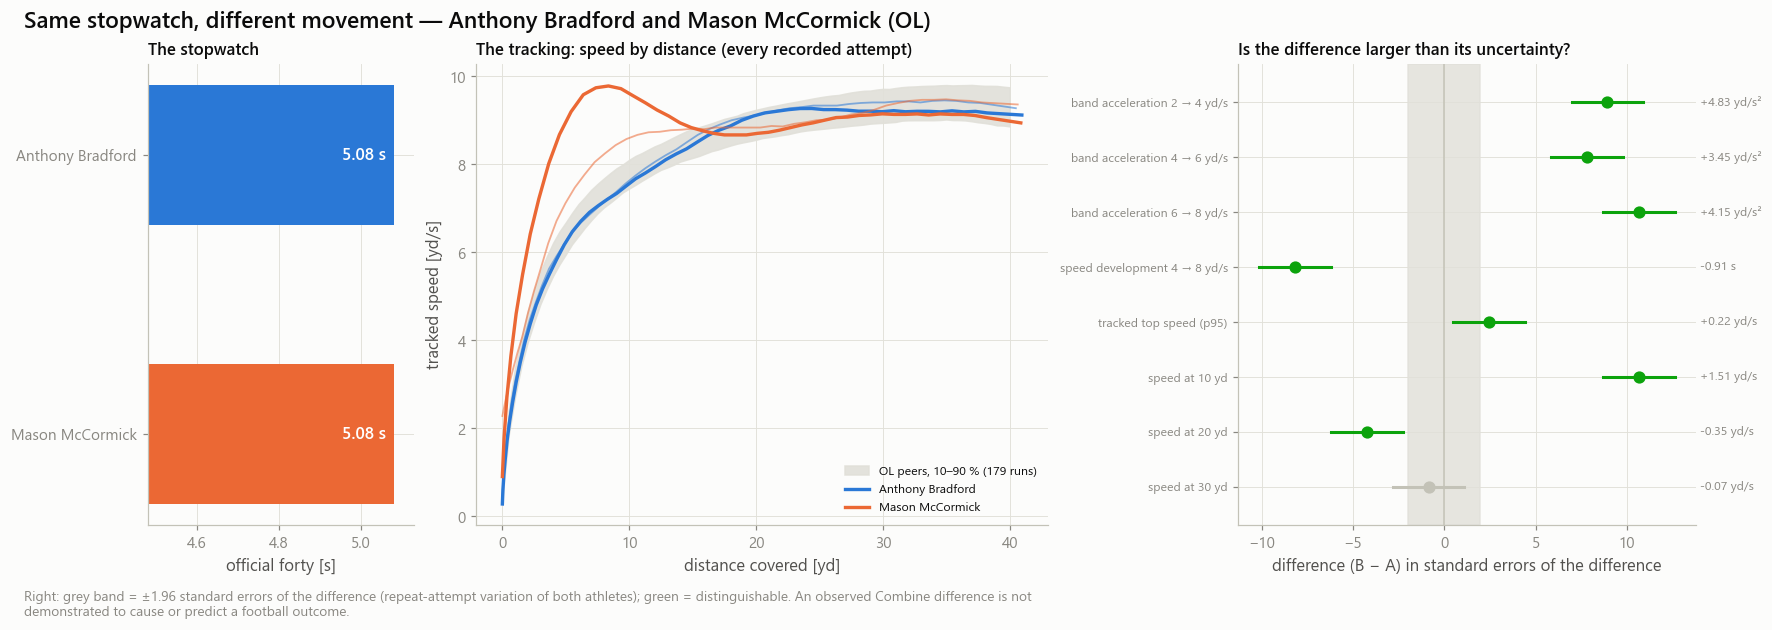

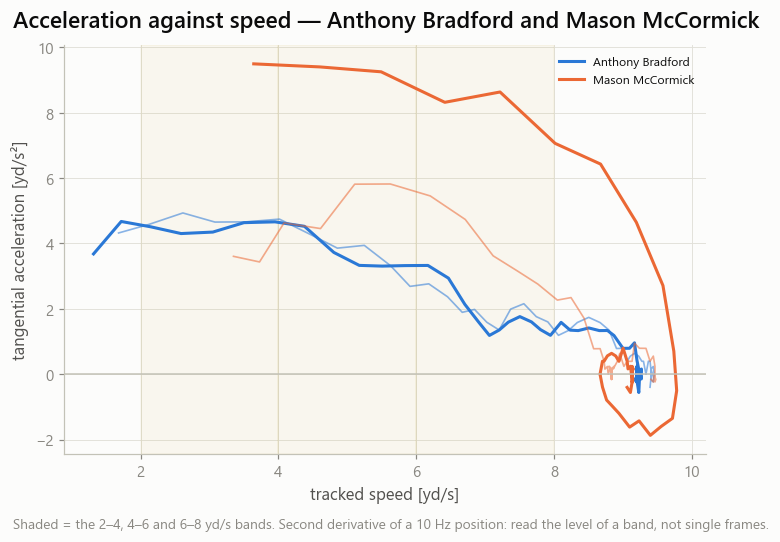

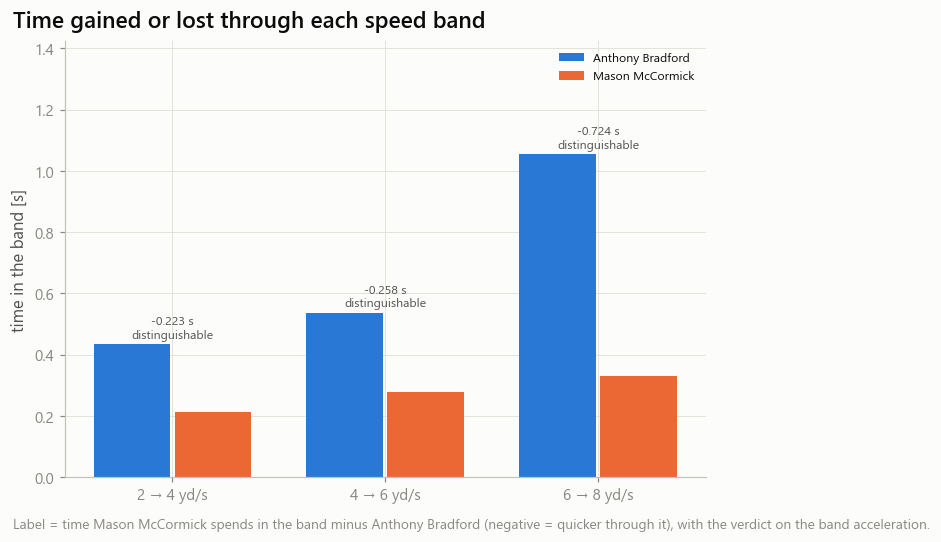

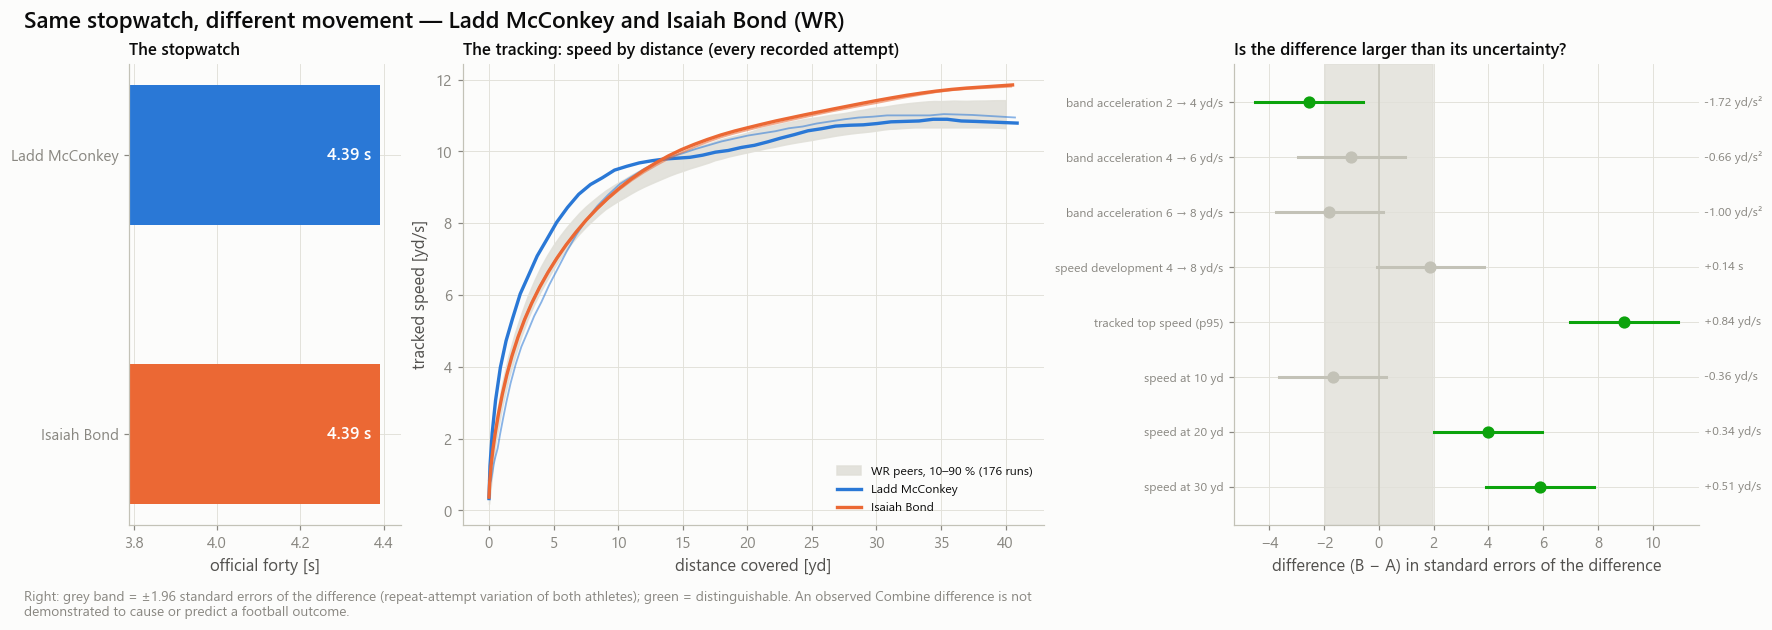

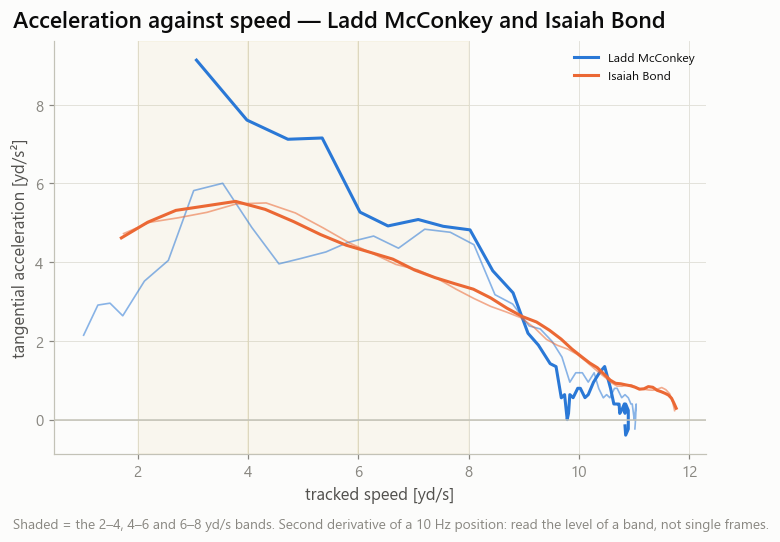

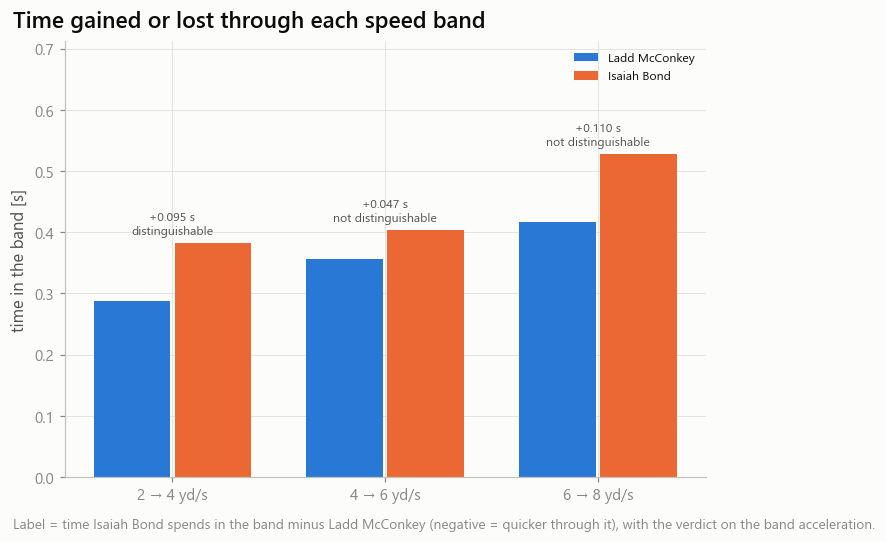

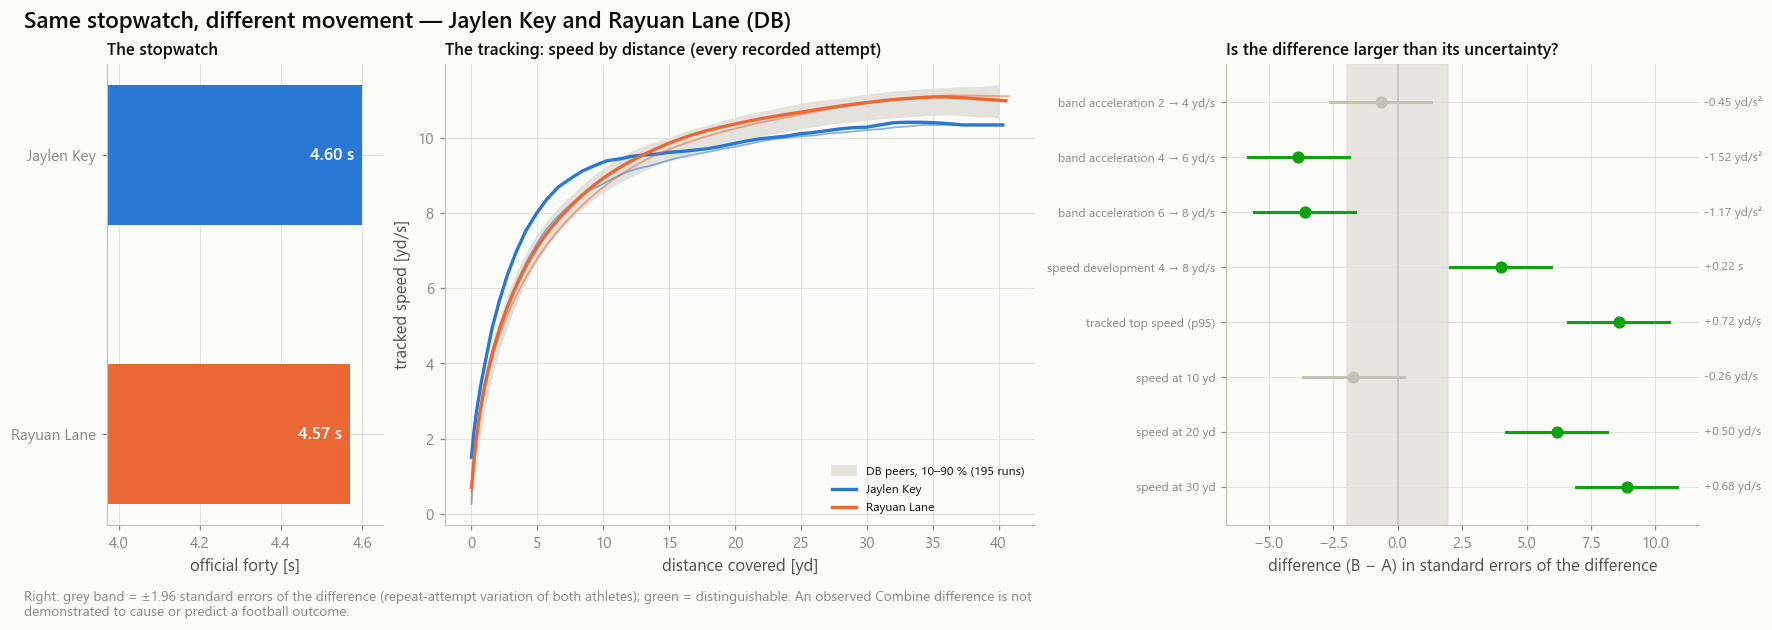

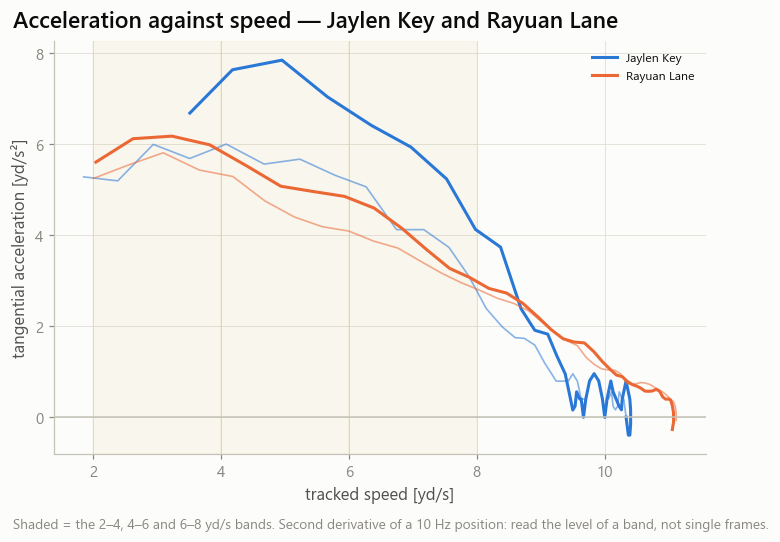

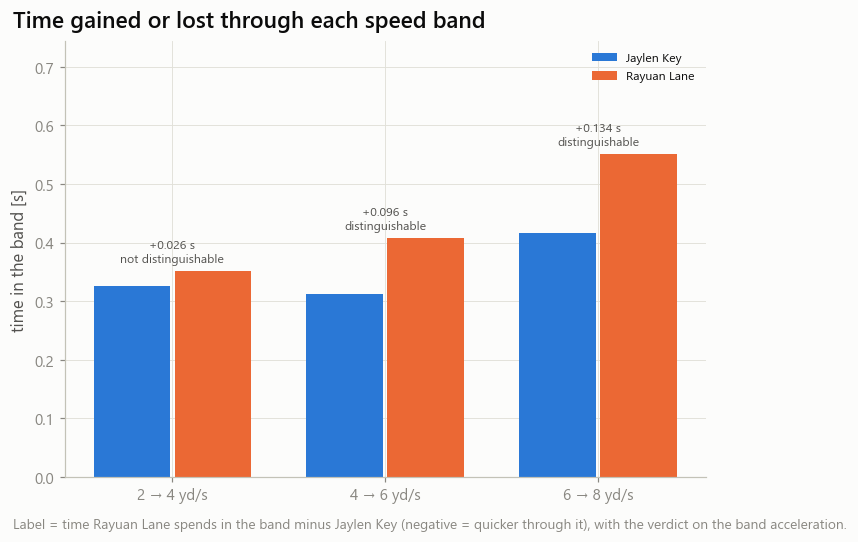

In [6]:
seqs = lambda i: windows.filter(pl.col('nfl_id') == i).sort('attempt_order')['seq_id'].to_list()[:2]
bands = {p: sfig.curve_band(frames, g['seq_id'].to_list()) for (p,), g in windows.partition_by(['position_group'], as_dict=True).items()}
stories = twins.filter(pl.col('rank_in_position') == 1).sort('max_abs_z', descending=True).head(N_STORIES)
for r in stories.iter_rows(named=True):
    d = diffs.filter(pl.col('pair_id') == r['pair_id']).to_dicts()
    names = (r['name_a'], r['name_b'])
    ids = (r['nfl_id_a'], r['nfl_id_b'])
    curves = {n: sfig.athlete_curves(frames, seqs(i)) for n, i in zip(names, ids)}
    store.show(ifg.fig_twin_story(r, curves, bands.get(r['position_group']), d), f'AM09C_02_twin_story_{r["pair_id"]}', {'differences': diffs.filter(pl.col('pair_id') == r['pair_id'])},
               publication=True, source='stopwatch_twins + stopwatch_twin_differences + sequence_frames', n='two athletes, every recorded attempt')
    prof = {n: ifg.traces(frames.filter(~pl.col('boundary')), seqs(i), 'speed', 'a_tan') for n, i in zip(names, ids)}
    store.show(ifg.fig_accel_speed(prof, f'Acceleration against speed — {names[0]} and {names[1]}'), f'AM09C_03_acceleration_speed_profile_{r["pair_id"]}', {},
               publication=True, source='sequence_frames (interior frames)', n='two athletes')
    store.show(ifg.fig_band_time(d, names), f'AM09C_04_time_through_speed_bands_{r["pair_id"]}', {}, publication=True, source='stopwatch_twin_differences', n='two athletes')
if stories.is_empty():
    print('no ranked pair: figures skipped')

## 5 · Reading and output contract

| Output | Grain |
|---|---|
| `stopwatch_twins` | athlete pair (the comparable-athlete search index, ranked) |
| `stopwatch_twin_differences` | pair × feature |
| `stopwatch_twin_summary` | position × feature |

**For a scout.** A distinguishable difference names a *movement phase* worth a second look on film or in a targeted test. A difference that is not distinguishable should not be read as a difference. Neither says which prospect will play better: that has not been established for any tracked Combine feature.

In [7]:
placeholder_cases = stw.CASES.empty()
reading = stw.conclusions(twins, summary, placeholder_cases)[:-1]
display(Markdown('\n'.join('- ' + s for s in reading)))
if controls.save_tables:
    store.write_json('stopwatch_twins_manifest', {'experiment_version': EXPERIMENT_VERSION, 'finished_at': utc_now(), 'n_pairs': twins.height,
                                                  'n_ranked': int(twins['rank_in_position'].is_not_null().sum()), 'fingerprint_distance': DIST is not None,
                                                  'story_pairs': stories['pair_id'].to_list(), 'reading': reading, 'provenance': PROV})
print('Send back: the checks table, the per-position pair counts, the summary table, the top-ranked table, figures AM09C_01 and AM09C_02, and the reading above.')
print('Next: 09d_football_interpretation_and_case_studies.ipynb')

- 3,266 stopwatch-twin pairs among 421 athletes; 2,097 pairs have at least one distinguishable curve feature.
- acc_2_4: 15 % of 3,128 tested pairs distinguishable (5 % expected by chance; pairs are not independent).
- acc_4_6: 16 % of 3,128 tested pairs distinguishable (5 % expected by chance; pairs are not independent).
- acc_6_8: 14 % of 3,128 tested pairs distinguishable (5 % expected by chance; pairs are not independent).
- speed_10yd: 17 % of 3,128 tested pairs distinguishable (5 % expected by chance; pairs are not independent).
- speed_20yd: 26 % of 3,128 tested pairs distinguishable (5 % expected by chance; pairs are not independent).
- speed_30yd: 38 % of 3,128 tested pairs distinguishable (5 % expected by chance; pairs are not independent).
- time_4_8: 21 % of 3,128 tested pairs distinguishable (5 % expected by chance; pairs are not independent).
- top_speed: 40 % of 3,128 tested pairs distinguishable (5 % expected by chance; pairs are not independent).

Send back: the checks table, the per-position pair counts, the summary table, the top-ranked table, figures AM09C_01 and AM09C_02, and the reading above.
Next: 09d_football_interpretation_and_case_studies.ipynb
